In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

file_name = 'combined_dataset.csv'
kaggle_input = Path('/kaggle/input')
possible_files = []
if kaggle_input.exists():
    possible_files.extend(kaggle_input.rglob(file_name))

data_path = next((path for path in possible_files if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        f'Could not find {file_name}. Upload it to Kaggle Input or put it next to this notebook.'
    )

df = pd.read_csv(data_path)
print('Loaded:', data_path)
print('Rows and columns:', df.shape)
display(df.head())

Loaded: /kaggle/input/datasets/jjingi/combined-dataset/combined_dataset.csv
Rows and columns: (417, 134)


,brand,specialty,campaign_start_date,unique_reach,unique_engaged_hcps,total_engagements,budget_spent_to_date,engagement_rate,engagement_frequency,pre_NRx,...,country_zwe,start_quarter_1,start_quarter_2,start_quarter_3,start_quarter_4,start_quarter_Unknown,budget_per_reach,budget_per_baseline_NRx,log_totalSpend,log_reach
0,ABBVIE,undefined,2024-07-31 10:48:34+00:00,9270.0,1070.0,4449.0,173511.0,0.1154,4.16,946.88,...,0,0,0,1,0,0,18.717476,3655.063891,18.715998,9.134647
1,ABBVIE,undefined,2024-08-19 17:16:44+00:00,1959.0,380.0,1178.0,45942.0,0.1940,3.10,915.49,...,0,0,0,1,0,0,23.451761,732.922485,16.182745,7.580700
2,ABBVIE,urology,2023-11-16 15:54:10+00:00,2860.0,403.0,1703.0,66417.0,0.1409,4.23,721.23,...,0,0,0,0,1,0,23.222727,1002.955242,17.894792,7.958926
3,ABBVIE,undefined,2024-11-22 10:27:31+00:00,7390.0,910.0,1107.0,43173.0,0.1231,1.22,1022.39,...,0,0,0,0,1,0,5.842084,773.303624,18.639718,8.908018
4,ABBVIE,NaN,2023-11-16 17:38:18+00:00,77570.0,26264.0,116027.0,348081.0,0.3386,4.42,630.86,...,0,0,0,0,1,0,4.487315,8849.231974,20.609436,11.258949


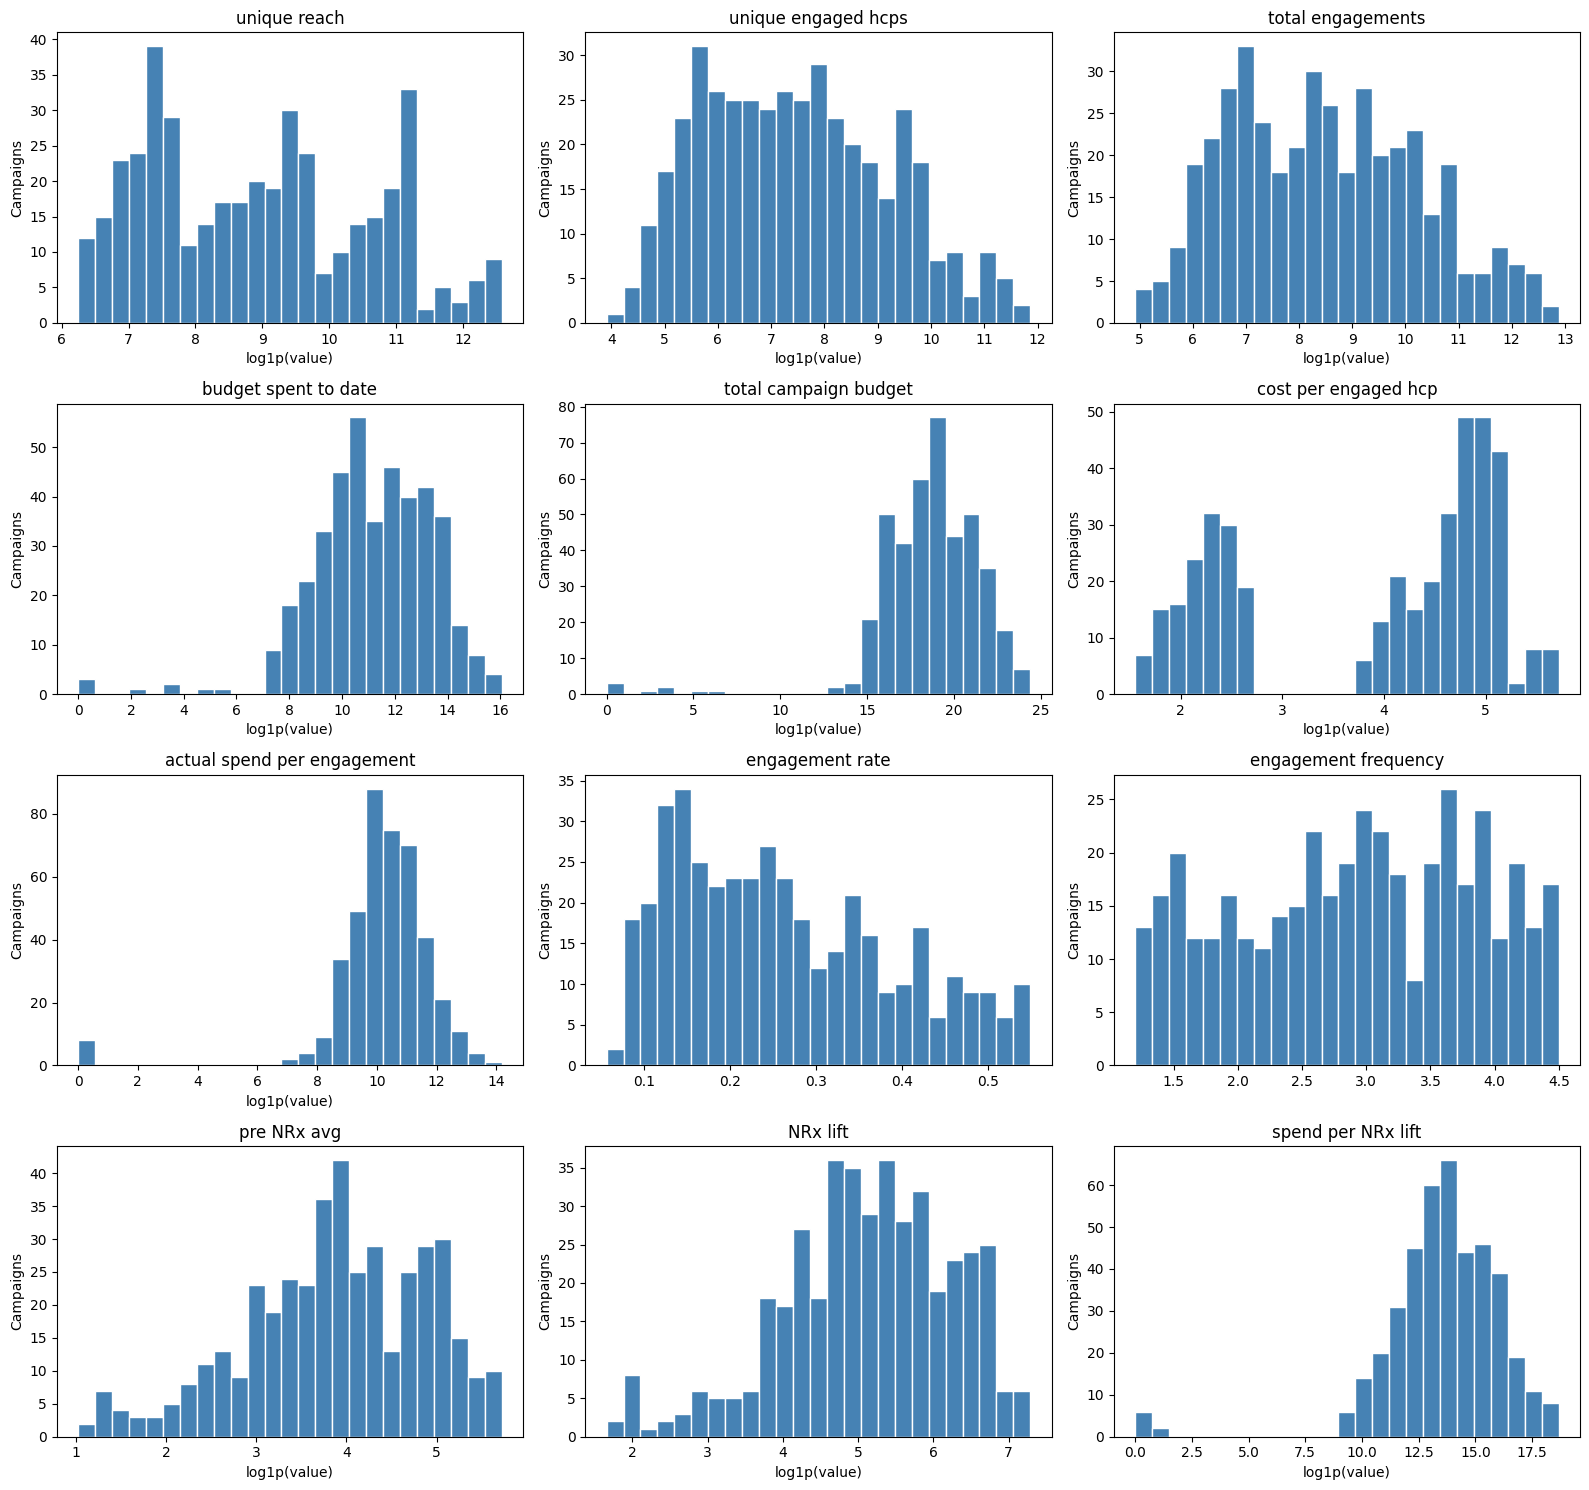

In [3]:
numeric_cols = [
    'unique_reach', 'unique_engaged_hcps', 'total_engagements',
    'budget_spent_to_date', 'total_campaign_budget',
    'cost_per_engaged_hcp', 'actual_spend_per_engagement',
    'engagement_rate', 'engagement_frequency',
    'pre_NRx_avg', 'NRx_lift', 'spend_per_NRx_lift',
]
log_view = {
    'unique_reach', 'unique_engaged_hcps', 'total_engagements',
    'budget_spent_to_date', 'total_campaign_budget',
    'cost_per_engaged_hcp', 'actual_spend_per_engagement',
    'pre_NRx_avg', 'NRx_lift', 'spend_per_NRx_lift',
}

fig, axes = plt.subplots(4, 3, figsize=(16, 15))
for ax, col in zip(axes.flat, numeric_cols):
    values = pd.to_numeric(df[col], errors='coerce')
    values = values.replace([np.inf, -np.inf], np.nan).dropna()
    if col in log_view:
        values = np.log1p(values[values >= 0])
        ax.set_xlabel('log1p(value)')
    ax.hist(values, bins=25, color='steelblue', edgecolor='white')
    ax.set_title(col.replace('_', ' '))
    ax.set_ylabel('Campaigns')
plt.tight_layout()
plt.show()

Missing or invalid start dates: 3


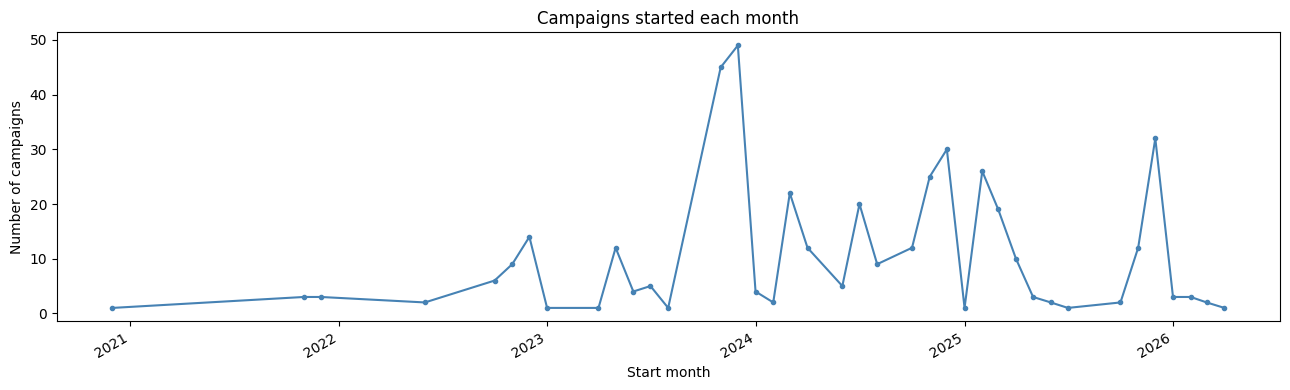

,count,median
start_year,,
2020.0,1,73164.0
2021.0,6,30478.5
2022.0,31,274380.0
2023.0,118,132429.0
2024.0,141,64701.0
2025.0,108,57154.5
2026.0,9,17004.0


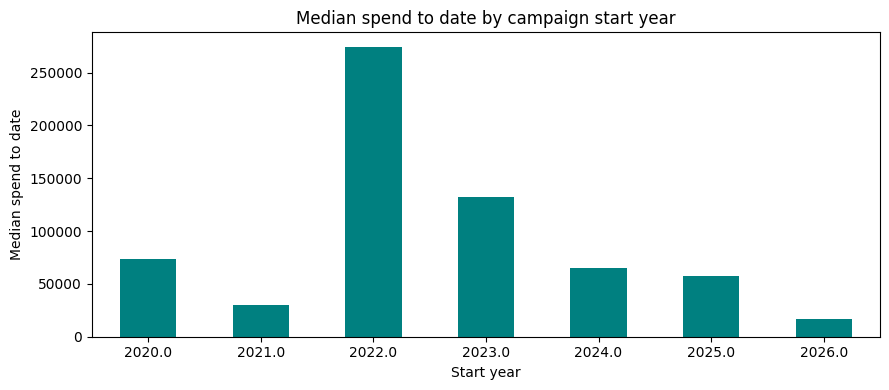

In [4]:
start_date = pd.to_datetime(df['campaign_start_date'], errors='coerce', utc=True)
print('Missing or invalid start dates:', start_date.isna().sum())

monthly_starts = (
    start_date.dropna().dt.tz_convert(None).dt.to_period('M')
    .value_counts().sort_index()
)
monthly_starts.index = monthly_starts.index.to_timestamp()

plt.figure(figsize=(13, 4))
monthly_starts.plot(color='steelblue', marker='o', markersize=3)
plt.title('Campaigns started each month')
plt.xlabel('Start month')
plt.ylabel('Number of campaigns')
plt.tight_layout()
plt.show()

spend_by_year = pd.DataFrame({
    'start_year': start_date.dt.year,
    'spend_to_date': pd.to_numeric(df['budget_spent_to_date'], errors='coerce'),
}).dropna(subset=['start_year'])
year_summary = spend_by_year.groupby('start_year')['spend_to_date'].agg(['count', 'median'])
display(year_summary)

ax = year_summary['median'].plot.bar(figsize=(9, 4), color='teal')
ax.set_title('Median spend to date by campaign start year')
ax.set_xlabel('Start year')
ax.set_ylabel('Median spend to date')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

brand: 73 displayed values including Missing


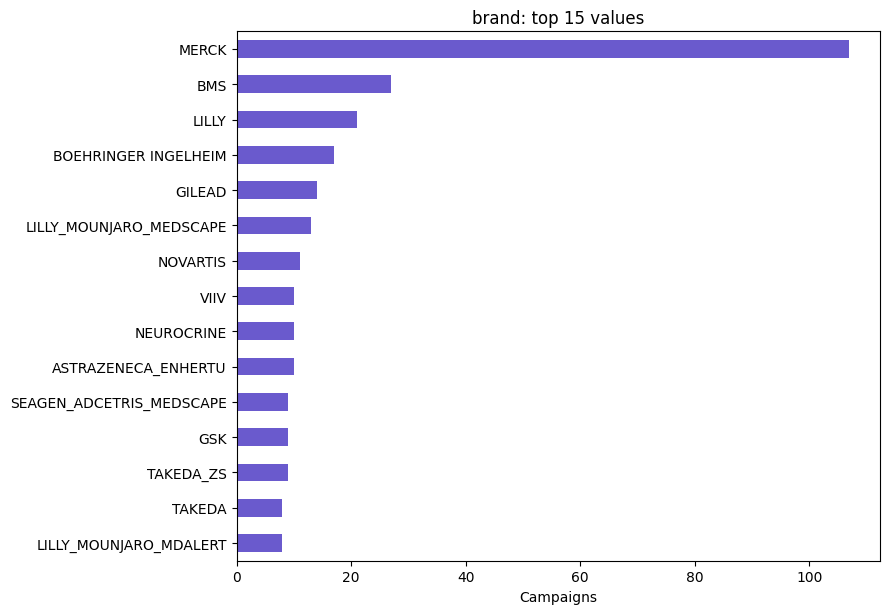

specialty: 10 displayed values including Missing


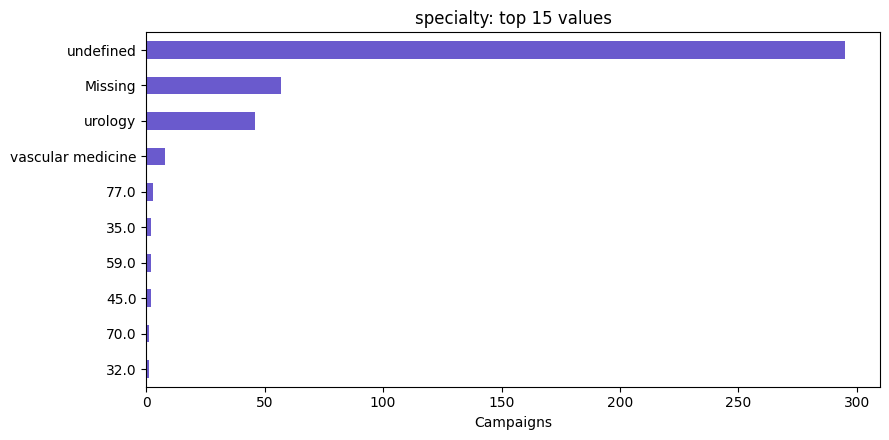

region: 10 displayed values including Missing


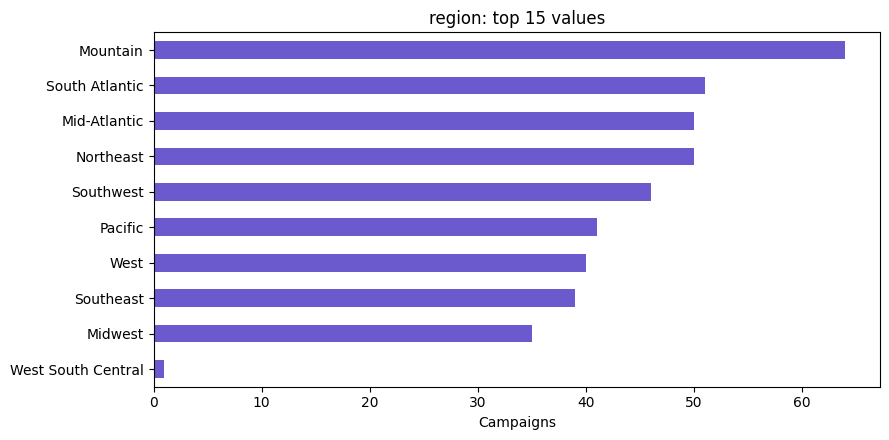

In [5]:
def category_bar(counts, title, color='slateblue'):
    counts = counts.sort_values()
    ax = counts.plot.barh(figsize=(9, max(3, 0.35 * len(counts) + 1)), color=color)
    ax.set_title(title)
    ax.set_xlabel('Campaigns')
    ax.set_ylabel('')
    plt.tight_layout()
    plt.show()

for col in ['brand', 'specialty', 'region']:
    counts = df[col].fillna('Missing').astype(str).value_counts()
    print(f'{col}: {len(counts)} displayed values including Missing')
    category_bar(counts.head(15), f'{col}: top 15 values')

brand_clean: 34 categories; showing top 15


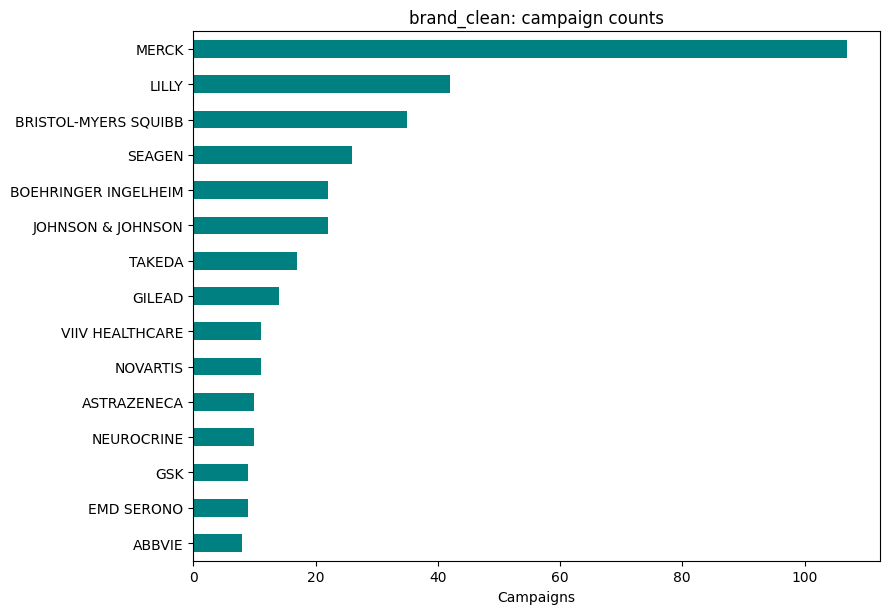

sub_product_name: 11 categories; showing top 11


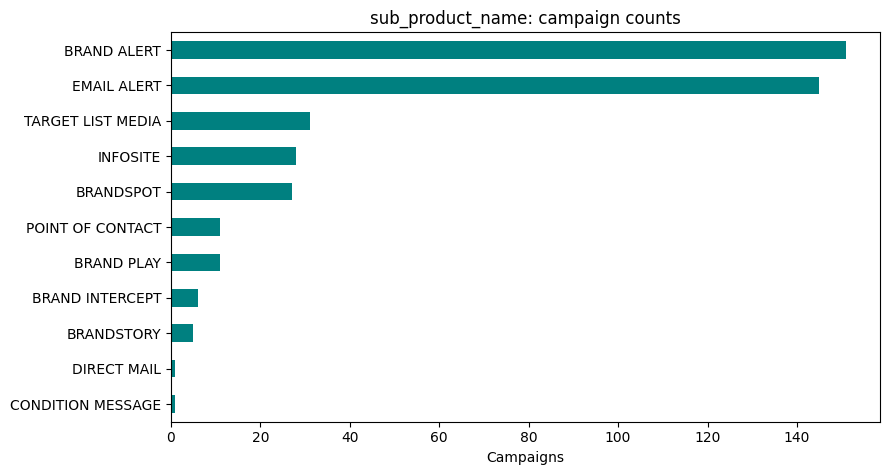

pillar: 5 categories; showing top 5


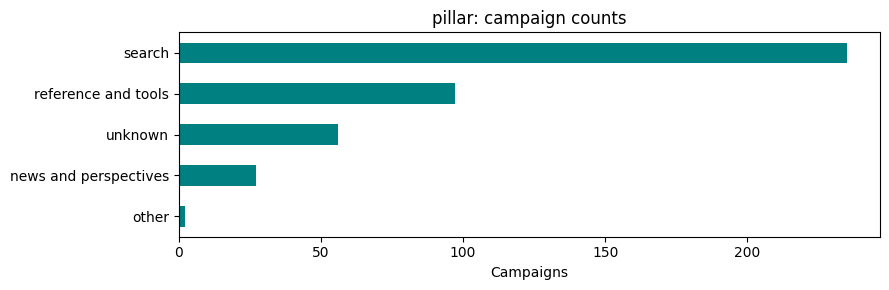

media_type: 3 categories; showing top 3


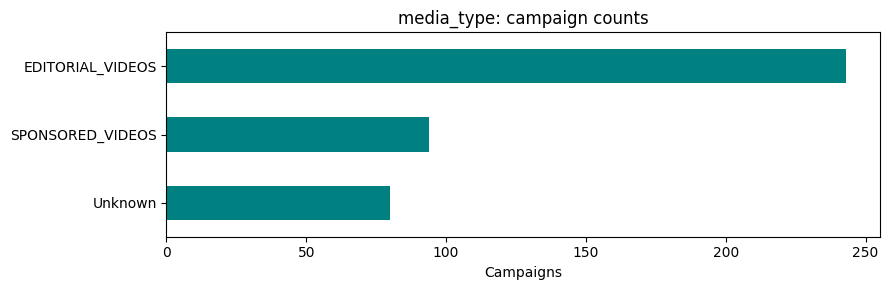

profession: 14 categories; showing top 14


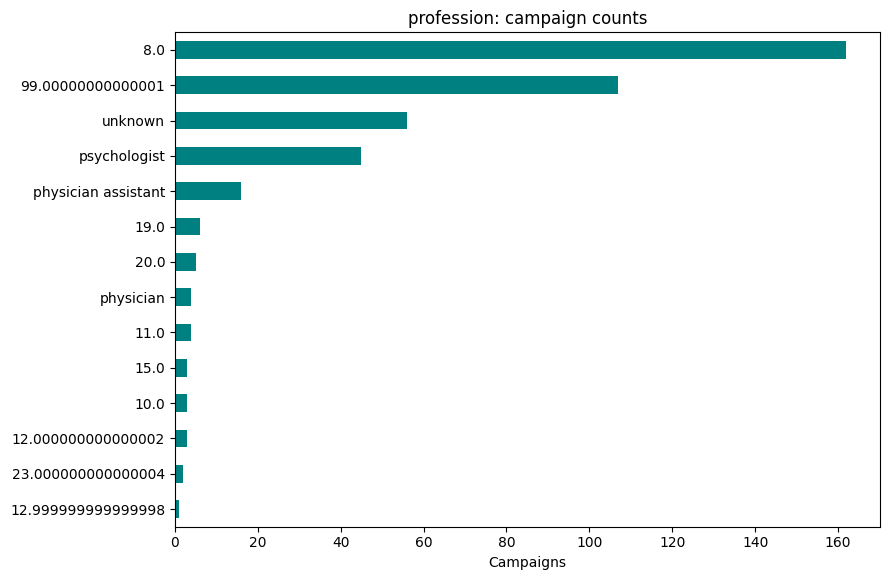

npi_specialty: 14 categories; showing top 14


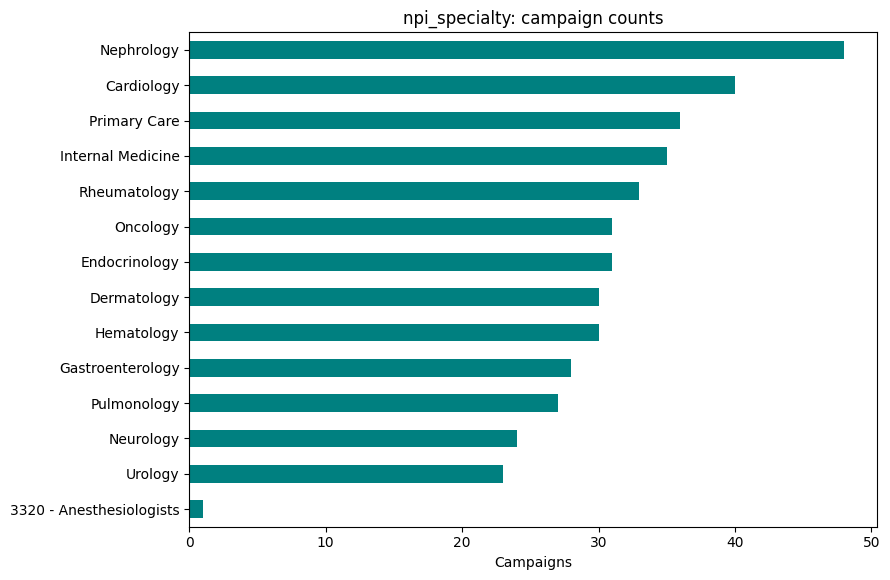

country: 9 categories; showing top 9


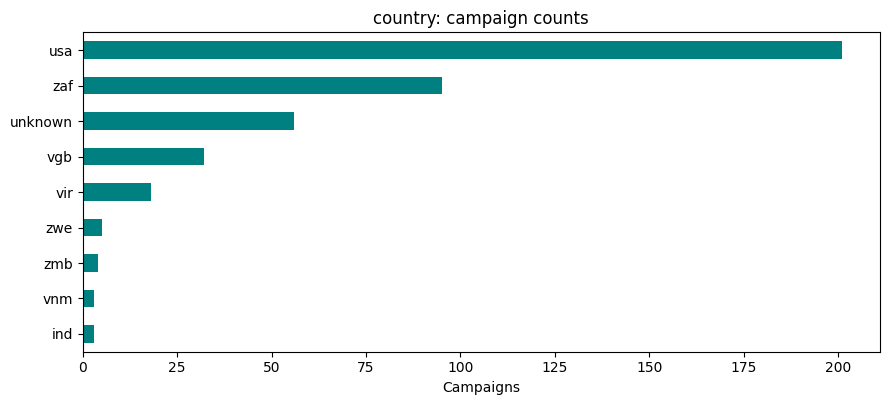

In [6]:
category_groups = {
    'brand_clean': 15,
    'sub_product_name': 15,
    'pillar': 15,
    'media_type': 15,
    'profession': 15,
    'npi_specialty': 15,
    'country': 15,
}

for group, top_n in category_groups.items():
    prefix = group + '_'
    columns = [col for col in df.columns if col.startswith(prefix)]
    if not columns:
        print(f'No columns found for {group}')
        continue
    counts = df[columns].apply(pd.to_numeric, errors='coerce').sum().sort_values(ascending=False)
    counts.index = counts.index.str.removeprefix(prefix)
    print(f'{group}: {len(counts)} categories; showing top {min(top_n, len(counts))}')
    category_bar(counts.head(top_n), f'{group}: campaign counts', color='teal')

,missing_rows,percent_of_rows
specialty,57,13.7
log_budget_spent_to_date,8,1.9
cost_per_engaged_hcp,8,1.9
clean_budget_spent_to_date,8,1.9
log_total_campaign_budget,3,0.7
campaign_start_date,3,0.7
planned_budget_per_baseline_NRx,3,0.7


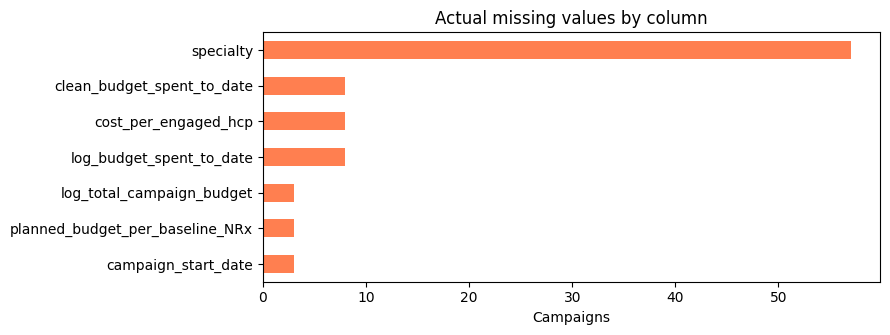

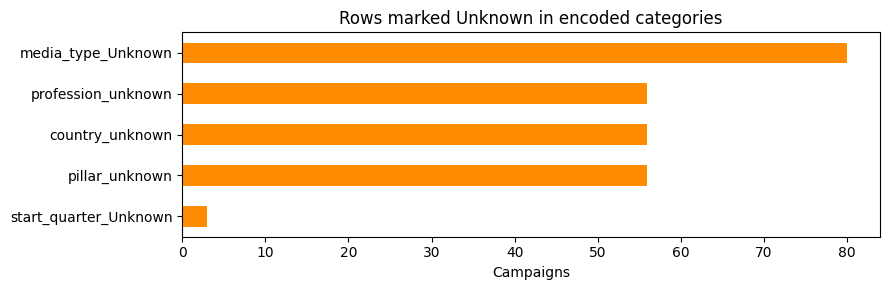

Rows where cpe equals 0: 93


In [7]:
missing_counts = df.isna().sum().sort_values(ascending=False)
missing_counts = missing_counts[missing_counts > 0]
missing_table = pd.DataFrame({
    'missing_rows': missing_counts,
    'percent_of_rows': (100 * missing_counts / len(df)).round(1),
})
display(missing_table)

if not missing_counts.empty:
    category_bar(missing_counts, 'Actual missing values by column', color='coral')
else:
    print('No actual null values found.')

unknown_cols = [
    col for col in df.columns
    if col.lower().endswith('_unknown')
    and col.startswith(('pillar_', 'media_type_', 'profession_', 'country_', 'start_quarter_'))
]
unknown_counts = df[unknown_cols].apply(pd.to_numeric, errors='coerce').sum()
unknown_counts = unknown_counts[unknown_counts > 0]
if not unknown_counts.empty:
    category_bar(unknown_counts, 'Rows marked Unknown in encoded categories', color='darkorange')

print('Rows where cpe equals 0:', pd.to_numeric(df['cpe'], errors='coerce').eq(0).sum())

In [8]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "/kaggle/input/datasets/jjingi/combined-dataset/combined_dataset.csv"
)

print(df.shape)
display(df.head())

(417, 134)


,brand,specialty,campaign_start_date,unique_reach,unique_engaged_hcps,total_engagements,budget_spent_to_date,engagement_rate,engagement_frequency,pre_NRx,...,country_zwe,start_quarter_1,start_quarter_2,start_quarter_3,start_quarter_4,start_quarter_Unknown,budget_per_reach,budget_per_baseline_NRx,log_totalSpend,log_reach
0,ABBVIE,undefined,2024-07-31 10:48:34+00:00,9270.0,1070.0,4449.0,173511.0,0.1154,4.16,946.88,...,0,0,0,1,0,0,18.717476,3655.063891,18.715998,9.134647
1,ABBVIE,undefined,2024-08-19 17:16:44+00:00,1959.0,380.0,1178.0,45942.0,0.1940,3.10,915.49,...,0,0,0,1,0,0,23.451761,732.922485,16.182745,7.580700
2,ABBVIE,urology,2023-11-16 15:54:10+00:00,2860.0,403.0,1703.0,66417.0,0.1409,4.23,721.23,...,0,0,0,0,1,0,23.222727,1002.955242,17.894792,7.958926
3,ABBVIE,undefined,2024-11-22 10:27:31+00:00,7390.0,910.0,1107.0,43173.0,0.1231,1.22,1022.39,...,0,0,0,0,1,0,5.842084,773.303624,18.639718,8.908018
4,ABBVIE,NaN,2023-11-16 17:38:18+00:00,77570.0,26264.0,116027.0,348081.0,0.3386,4.42,630.86,...,0,0,0,0,1,0,4.487315,8849.231974,20.609436,11.258949


# Predictive Modeling: NRx Lift

# 1. Target Variable Selection
# 2. Feature Selection
# 3. Training and Validation Split (80/20)
# 4. Model Training
# 5. Model Evaluation
# 6. Results and Interpretation



In [9]:
import os

folder = "/kaggle/input/datasets/jjingi/combined-dataset"

print(os.listdir(folder))

['combined_dataset.csv']


In [10]:
import pandas as pd
import glob

csv_files = glob.glob(
    "/kaggle/input/datasets/jjingi/combined-dataset/**/*.csv",
    recursive=True
)

print("CSV files found:", csv_files)

CSV files found: ['/kaggle/input/datasets/jjingi/combined-dataset/combined_dataset.csv']


In [11]:

import pandas as pd
import numpy as np

# Keep valid spending observations
spend_df = df.dropna(
    subset=["clean_budget_spent_to_date"]
).copy()

# Target variable
y_spend = spend_df["clean_budget_spent_to_date"]

# Campaign setup feature groups
prefixes = (
    "brand_clean_",
    "sub_product_name_",
    "pillar_",
    "media_type_",
    "npi_specialty_",
    "country_",
    "start_quarter_"
)

# Select existing one-hot encoded columns
feature_cols = [
    col for col in spend_df.columns
    if col.startswith(prefixes)
]

# Drop one dummy column per group to avoid redundancy
reference_cols = [
    next(col for col in feature_cols if col.startswith(prefix))
    for prefix in prefixes
]

feature_cols = [
    col for col in feature_cols
    if col not in reference_cols
]

X_spend = spend_df[feature_cols].copy()

print("Observations:", len(y_spend))
print("Predictors:", X_spend.shape[1])
print("Missing values:", X_spend.isna().sum().sum())


Observations: 409
Predictors: 74
Missing values: 0


In [12]:

from sklearn.model_selection import train_test_split

X_train_s, X_val_s, y_train_s, y_val_s = train_test_split(
    X_spend,
    y_spend,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train_s))
print("Validation rows:", len(X_val_s))


Training rows: 327
Validation rows: 82


In [13]:

from sklearn.linear_model import LinearRegression

ols_model = LinearRegression()

ols_model.fit(X_train_s, y_train_s)

ols_pred = ols_model.predict(X_val_s)

print("OLS model trained successfully!")


OLS model trained successfully!


In [14]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

baseline = DummyRegressor(strategy="median")
baseline.fit(X_train_s, y_train_s)

baseline_pred = baseline.predict(X_val_s)

def get_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted)
    }

results_table = pd.DataFrame({
    "Baseline": get_metrics(y_val_s, baseline_pred),
    "OLS Regression": get_metrics(y_val_s, ols_pred)
})

display(results_table.round(2))


,Baseline,OLS Regression
MAE,498454.73,542720.97
RMSE,1266382.04,1087124.59
R²,-0.15,0.15


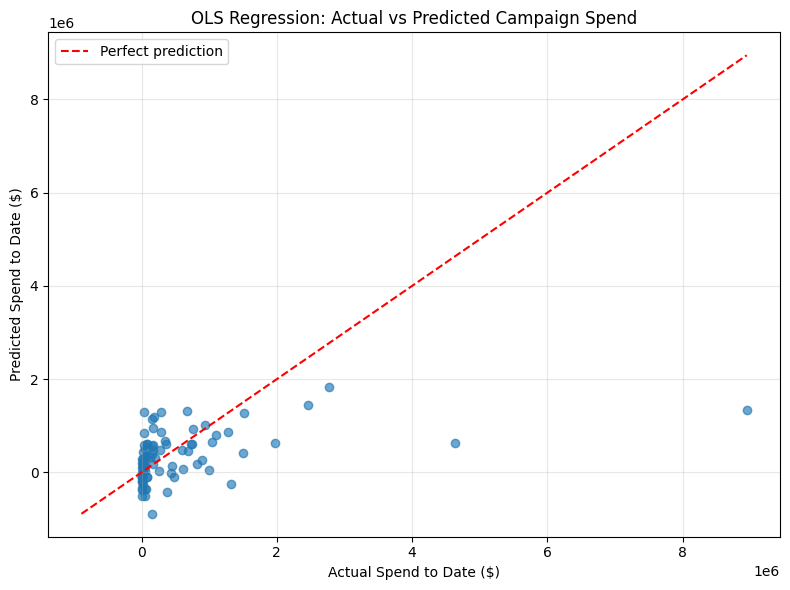

In [15]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val_s,
    ols_pred,
    alpha=0.65
)

max_value = max(y_val_s.max(), ols_pred.max())
min_value = min(y_val_s.min(), ols_pred.min(), 0)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Spend to Date ($)")
plt.ylabel("Predicted Spend to Date ($)")
plt.title("OLS Regression: Actual vs Predicted Campaign Spend")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [16]:

coefficients = pd.DataFrame({
    "Feature": X_spend.columns,
    "Coefficient": ols_model.coef_
})

coefficients["Absolute_Coefficient"] = (
    coefficients["Coefficient"].abs()
)

display(
    coefficients.sort_values(
        "Absolute_Coefficient",
        ascending=False
    ).head(15)
)


,Feature,Coefficient,Absolute_Coefficient
64,country_vgb,884511.461797,884511.461797
4,brand_clean_BOEHRINGER INGELHEIM,878354.792828,878354.792828
2,brand_clean_ASTELLAS,-820401.569590,820401.569590
38,sub_product_name_DIRECT MAIL,-801888.565822,801888.565822
33,sub_product_name_BRAND INTERCEPT,-791959.003982,791959.003982
68,country_zmb,556232.332853,556232.332853
65,country_vir,502240.325632,502240.325632
67,country_zaf,489211.748908,489211.748908
11,brand_clean_GILEAD,487506.773073,487506.773073
52,npi_specialty_Gastroenterology,436317.731447,436317.731447


In [17]:

from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Standard OLS with log-transformed target
log_ols = TransformedTargetRegressor(
    regressor=LinearRegression(),
    func=np.log1p,
    inverse_func=np.expm1
)

# Train on exactly the same dataset
log_ols.fit(X_train_s, y_train_s)

# Predict spend in original dollar units
log_pred = log_ols.predict(X_val_s)

print("Log-OLS MAE:",
      round(mean_absolute_error(y_val_s, log_pred), 2))

print("Log-OLS RMSE:",
      round(np.sqrt(mean_squared_error(y_val_s, log_pred)), 2))

print("Log-OLS R²:",
      round(r2_score(y_val_s, log_pred), 3))

print("Negative predictions:",
      (log_pred < 0).sum())


Log-OLS MAE: 392515.72
Log-OLS RMSE: 1111957.28
Log-OLS R²: 0.115
Negative predictions: 0


In [19]:

# Compare error metrics for different spending ranges

evaluation = pd.DataFrame({
    "Actual": y_val_s.to_numpy(),
    "OLS_Predicted": ols_pred,
    "Log_OLS_Predicted": log_pred
})

evaluation["Spend_Group"] = pd.qcut(
    evaluation["Actual"],
    q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

evaluation["OLS_Error"] = abs(
    evaluation["Actual"] - evaluation["OLS_Predicted"]
)

evaluation["Log_OLS_Error"] = abs(
    evaluation["Actual"] - evaluation["Log_OLS_Predicted"]
)

group_errors = evaluation.groupby(
    "Spend_Group",
    observed=True
)[["OLS_Error", "Log_OLS_Error"]].mean()

display(group_errors.round(2))


,OLS_Error,Log_OLS_Error
Spend_Group,,
Low,186765.36,12773.78
Medium-Low,379779.07,102476.45
Medium-High,496531.22,202272.48
High,1097849.57,1229669.57


In [20]:

comparison = pd.DataFrame({
    "Median Baseline": get_metrics(
        y_val_s, baseline_pred
    ),
    "OLS": get_metrics(
        y_val_s, ols_pred
    ),
    "Log-OLS": get_metrics(
        y_val_s, log_pred
    )
})

display(comparison.round(2))


,Median Baseline,OLS,Log-OLS
MAE,498454.73,542720.97,392515.72
RMSE,1266382.04,1087124.59,1111957.28
R²,-0.15,0.15,0.11


### Initial OLS Regression Results

We developed an Ordinary Least Squares (OLS) regression model to predict pharmaceutical campaign spending to date using 74 campaign setup features.

The dataset was divided into 80% training and 20% validation observations. We evaluated the model using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R², comparing its performance against a median-spend baseline.

The OLS model achieved an MAE of $542,721, RMSE of $1,087,125, and R² of 0.154. While it improved RMSE relative to the baseline, its average absolute prediction error was higher than simply predicting the median historical campaign spend.

Visual analysis revealed substantial underprediction of the most expensive campaigns, as well as negative predictions that are not economically meaningful.

These findings suggest that a standard linear relationship between the available setup features and campaign spend may be insufficient to capture the wide variation in historical spending.

Our next experiment will apply a logarithmic transformation to the spending target while retaining ordinary linear regression, allowing us to evaluate whether the model performs better when the influence of exceptionally large campaigns is reduced.

In [21]:

comparison = pd.DataFrame({
    "Baseline": get_metrics(y_val_s, baseline_pred),
    "OLS": get_metrics(y_val_s, ols_pred),
    "Log-OLS": get_metrics(y_val_s, log_pred)
})

display(comparison.round(2))


,Baseline,OLS,Log-OLS
MAE,498454.73,542720.97,392515.72
RMSE,1266382.04,1087124.59,1111957.28
R²,-0.15,0.15,0.11


In [23]:

evaluation["OLS_Residual"] = (
    evaluation["Actual"] - evaluation["OLS_Predicted"]
)

evaluation["Log_OLS_Residual"] = (
    evaluation["Actual"] - evaluation["Log_OLS_Predicted"]
)

display(
    evaluation.groupby("Spend_Group", observed=True)[
        ["OLS_Residual", "Log_OLS_Residual"]
    ].mean().round(2)
)


,OLS_Residual,Log_OLS_Residual
Spend_Group,,
Low,45128.73,-9656.97
Medium-Low,-202265.82,-70117.28
Medium-High,-140901.89,138818.66
High,1012747.81,1229669.57
